In [2]:
import matplotlib.pyplot as plt
from pathlib import Path
import kagglehub


import imagehash
from PIL import Image
import os
import re
import pathlib
import pandas as pd
from PIL import Image
import numpy as np
import reverse_geocoder as rg
import pycountry
import pycountry_convert as pc
import plotly.express as px
import plotly.offline as pyo


import plotly.graph_objects as go
from plotly.offline import init_notebook_mode, iplot

from math import ceil, sqrt

# Import inbuilt libraries
import os, shutil, pathlib
from math import sqrt, ceil

# Import necessary libraries for data analysis
import numpy as np
import pandas as pd

# Import necessary libraries for data visualization
from plotly.offline import init_notebook_mode, iplot
import plotly.graph_objects as go
import plotly.offline as pyo
import plotly.express as px

# Initialize Plotly for Jupyter notebook
init_notebook_mode(connected=True)
import cv2


/home/pedrosalgado22/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
IMAGES_PATH = Path() / "images" / "classification"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)




plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [4]:
DATA_PATH = Path("data/images/streetview_images")

if not any(DATA_PATH.iterdir()):
    path = kagglehub.dataset_download(
        "sylshaw/streetview-by-country",
        output_dir=str(DATA_PATH)
    )
else:
    path = str(DATA_PATH)

print("Path to dataset:", path)

Path to dataset: data/images/streetview_images


In [5]:
geo_data_dir = pathlib.Path(path)


def extract_metadata_from_folder(path):
    metadata = []
    for file_path in path.glob('*'):   # loops through every item inside path
        width, height = Image.open(file_path).size

        lat_str, lon_str, heading_str = file_path.stem.split('_')
        latitude = float(lat_str.lstrip('n').replace('d', '.'))
        if lat_str.startswith('n'):
            latitude = -latitude
        longitude = float(lon_str.lstrip('n').replace('d', '.'))
        if lon_str.startswith('n'):
            longitude = -longitude
        heading = int(heading_str[1:])
        if heading_str.startswith('n'):
            heading = -heading

        metadata.append({
            'country_code': path.name,
            'image_name': file_path.name,
            'width': width,
            'height': height,
            'size': file_path.stat().st_size,
            'path': file_path,
            'latitude': latitude,
            'longitude': longitude,
            'heading': heading
        })
    return metadata



In [6]:
# List all country folders
country_folders = [f for f in os.listdir(geo_data_dir) if os.path.isdir(os.path.join(geo_data_dir, f))]

# Initialize an empty list to store metadata
all_metadata = []

# Iterate through country folders and extract metadata
for country_name in country_folders:
    metadata = extract_metadata_from_folder(pathlib.Path(os.path.join(geo_data_dir, country_name)))
    all_metadata.extend(metadata)

# Create a Pandas DataFrame from the metadata
df_geo_data = pd.DataFrame(all_metadata)

def get_country_codes(df):
    coords = list(zip(df['latitude'], df['longitude']))
    return [r['cc'] for r in rg.search(coords, mode=1)]

def get_country(codes):
    return [pycountry.countries.get(alpha_2=c).name if pycountry.countries.get(alpha_2=c) else c for c in codes]

def get_continent(codes):
    result = []
    for c in codes:
        try:
            result.append(pc.convert_continent_code_to_continent_name(pc.country_alpha2_to_continent_code(c)))
        except KeyError:
            result.append(None)
    return result

coord_codes = get_country_codes(df_geo_data)
df_geo_data['country'] = get_country(coord_codes)
df_geo_data['continent'] = get_continent(coord_codes)

df_data_distribution = df_geo_data.groupby('country')['image_name'].count().reset_index().rename(columns={'image_name': 'frequency'})

df_geo_data.head()

Loading formatted geocoded file...


,country_code,image_name,width,height,size,path,latitude,longitude,heading,country,continent
0,AD,42d436079_1d473612_h213.jpg,640,640,71291,data/images/streetview_images/AD/42d436079_1d4...,42.436079,1.473612,213,Andorra,Europe
1,AD,42d436223_1d521434_h252.jpg,640,640,86050,data/images/streetview_images/AD/42d436223_1d5...,42.436223,1.521434,252,Andorra,Europe
2,AD,42d437356_1d476157_h207.jpg,640,640,75563,data/images/streetview_images/AD/42d437356_1d4...,42.437356,1.476157,207,Andorra,Europe
3,AD,42d438534_1d521492_h237.jpg,640,640,99736,data/images/streetview_images/AD/42d438534_1d5...,42.438534,1.521492,237,Andorra,Europe
4,AD,42d439193_1d490868_h254.jpg,640,640,70899,data/images/streetview_images/AD/42d439193_1d4...,42.439193,1.490868,254,Andorra,Europe


In [7]:
df_geo_data['coord_country_code'] = coord_codes

mismatches = df_geo_data[df_geo_data['coord_country_code'] != df_geo_data['country_code']]

print(f"{len(mismatches)} mismatches")

mismatches[['image_name', 'country_code', 'coord_country_code', 'country']]

print(df_geo_data.isna().sum())

3572 mismatches
country_code          0
image_name            0
width                 0
height                0
size                  0
path                  0
latitude              0
longitude             0
heading               0
country               0
continent             2
coord_country_code    0
dtype: int64


In [8]:
df_geo_data[df_geo_data['continent'].isna()]

,country_code,image_name,width,height,size,path,latitude,longitude,heading,country,continent,coord_country_code
40268,ID,n9d182485_124d493443_h235.jpg,640,640,84598,data/images/streetview_images/ID/n9d182485_124...,-9.182485,124.493443,235,Timor-Leste,NaN,TL
45699,IT,41d934502_12d433915_h254.jpg,640,640,94682,data/images/streetview_images/IT/41d934502_12d...,41.934502,12.433915,254,Holy See (Vatican City State),NaN,VA


These 2 will be dropped so is ok

In [9]:
# select a random country
random_country = df_geo_data.sample(1)

with Image.open(random_country.path.values[0]) as img:
    fig = go.Figure()
    fig.add_trace(go.Image(z=img))
    fig.update_layout(
        title="Image from the training dataset",
        template="plotly_white",
        width=900,
        height=450
    )
    
    fig.update_xaxes(title_text="Width")
    fig.update_yaxes(title_text="Height")
    
    fig.add_annotation(
        x=0.5,
        y=1.1,
        xref="paper",
        yref="paper",
        text="Country : {}".format(random_country.country.values[0]),
        showarrow=False
    )
    
    fig.show()

In [10]:
print("The total number of images in the dataset are {:,} images.".format(df_data_distribution.frequency.sum()))
print("The average number of images per country is {:,} images.".format(int(df_data_distribution.frequency.mean())))
print("The median number of images per country is {:,} images.".format(int(df_data_distribution.frequency.median())))
print("25% of the countries have {:,} images or less, while 75% of the countries have {:,} images or more.".format(int(df_data_distribution.frequency.quantile(0.25)), int(df_data_distribution.frequency.quantile(0.75))))
print("The maximum and minimum number of images per country are {:,} and {:,} images respectively.".format(df_data_distribution.frequency.max(), df_data_distribution.frequency.min()))

The total number of images in the dataset are 107,269 images.
The average number of images per country is 719 images.
The median number of images per country is 976 images.
25% of the countries have 111 images or less, while 75% of the countries have 1,000 images or more.
The maximum and minimum number of images per country are 1,408 and 1 images respectively.


In [11]:
# Function to plot heatmap
def plot_heatmap(df, title_text, color_threshold=0.90):
    # Shaping Data to fit graph by finding the max size of the grid to fit all the images
    grid_size = ceil(sqrt(df.shape[0]))**2
    
    pad = '-'
    n_labels = df.country.to_list() + ([pad] * (grid_size - df.shape[0]))
    n_samples = df.frequency.to_list() + ([np.nan] * (grid_size - df.shape[0]))
    
    samples = np.split(np.array(n_samples), sqrt(grid_size))
    
    fig = go.Figure(data=go.Heatmap(
        z=samples,
        x0=0,
        dx=1,
        y0=0,
        dy=1,
        colorscale='Emrld',
        text=n_labels,
        hoverinfo='text',
    ))
    
    # Add labels within the heatmap
    for i, country in enumerate(df['country']):
        x_pos = i % int(sqrt(grid_size))
        y_pos = i // int(sqrt(grid_size))
        fig.add_annotation(
            x=x_pos,  # Center the label within the grid cell
            y=y_pos,
            text= "{}<br> Count: {}".format(n_labels[i].replace(' ', '<br>'), n_samples[i]),
            showarrow=False,
            font=dict(
                color='#474747' if n_samples[i] < df.frequency.quantile(color_threshold) else 'white',
                size=10),
        )
    
    # hide axis labels
    fig.update_xaxes(showticklabels=False)
    fig.update_yaxes(showticklabels=False, autorange='reversed')
    
    # change the dimensions of the figure
    fig.update_layout(
        title=title_text,
        height=1200,
        width=1200
    )
    fig = add_plot_styling(fig)
    
    # Use iplot to display the graph in the Jupyter Notebook
    pyo.iplot(fig)

In [12]:
# Function to add custom styling to the plot
def add_plot_styling(fig):
    fig.update_layout(
        plot_bgcolor='rgba(0,0,0,0.05)',  # Set background color to transparent
    )
    return fig



In [13]:
plot_heatmap(df_data_distribution.sort_values(by='frequency', ascending=True), "Images per Country", color_threshold=0.98)

In [14]:
df_geo_data.keys()

Index(['country_code', 'image_name', 'width', 'height', 'size', 'path',
       'latitude', 'longitude', 'heading', 'country', 'continent',
       'coord_country_code'],
      dtype='str')

In [15]:
# outlier removal
filtered_countries = df_data_distribution[(df_data_distribution.frequency >= 110) & (df_data_distribution.frequency <= 10000) ].country.unique()

df_filtered_geo_data = df_geo_data[df_geo_data.country.isin(filtered_countries)]


In [16]:
plot_heatmap(df_filtered_geo_data.groupby('country')['image_name'].count().reset_index().rename(columns={'image_name': 'frequency'}).sort_values(by='frequency', ascending=True), "Images per Country", color_threshold=0.98)

In [17]:
def check_corrupted(df):
    results = []
    for path in df['path']:
        img = cv2.imread(str(path))
        results.append(img is None)
    df['corrupted'] = results
    return df

In [18]:
def check_channels(df):
    results = []
    for path in df['path']:
        img = cv2.imread(str(path))
        results.append(img.shape[2] if img.ndim == 3 else 1)
    df['channels'] = results
    return df

In [19]:
def check_duplicates(df):
    results = []
    for path in df['path']:
        results.append(str(imagehash.phash(Image.open(path))))
    df['phash'] = results
    return df

In [20]:
df_filtered_geo_data = check_corrupted(df_filtered_geo_data)
df_filtered_geo_data = check_channels(df_filtered_geo_data)
df_filtered_geo_data = check_duplicates(df_filtered_geo_data)

print(df_filtered_geo_data['corrupted'].sum(), "corrupted images")
print(df_filtered_geo_data['channels'].value_counts())
print(df_filtered_geo_data['phash'].duplicated(keep=False).sum(), "images with a duplicate hash")

0 corrupted images
channels
3    106755
Name: count, dtype: int64
0 images with a duplicate hash


In [ ]:
import numpy as np

def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [22]:
train_set, test_set = shuffle_and_split_data(df_filtered_geo_data, 0.1)
len(train_set)

96080

In [23]:
len(test_set)

10675

In [24]:
np.random.seed(42)

In [25]:
from hsv import color_histogram

In [26]:
train_features = [color_histogram(path) for path in train_set['path']]
test_features = [color_histogram(path) for path in test_set['path']]

In [27]:
train_set.head()

,country_code,image_name,width,height,size,path,latitude,longitude,heading,country,continent,coord_country_code,corrupted,channels,phash
54713,LA,17d944426_102d719852_h183.jpg,640,640,46149,data/images/streetview_images/LA/17d944426_102...,17.944426,102.719852,183,Thailand,Asia,TH,False,3,cbeaaf0149e9d41a
71409,NG,10d618564_10d177281_h18.jpg,640,640,54398,data/images/streetview_images/NG/10d618564_10d...,10.618564,10.177281,18,Nigeria,Africa,NG,False,3,d5c5a62a4ada9535
77678,PA,8d266580_n80d985855_h120.jpg,640,640,87006,data/images/streetview_images/PA/8d266580_n80d...,8.266580,-80.985855,120,Panama,North America,PA,False,3,c4a4b56b2c99da27
27824,FI,63d969320_24d523132_h214.jpg,640,640,55555,data/images/streetview_images/FI/63d969320_24d...,63.969320,24.523132,214,Finland,Europe,FI,False,3,d9f1b73825c8d036
17105,CL,n44d202933_n72d498801_h19.jpg,640,640,80027,data/images/streetview_images/CL/n44d202933_n7...,-44.202933,-72.498801,19,Chile,South America,CL,False,3,8d87a6636353d4ac


In [28]:
test_set.head()

,country_code,image_name,width,height,size,path,latitude,longitude,heading,country,continent,coord_country_code,corrupted,channels,phash
26555,ES,40d546220_0d428451_h46.jpg,640,640,59218,data/images/streetview_images/ES/40d546220_0d4...,40.546220,0.428451,46,Spain,Europe,ES,False,3,f5e20b3443aed54a
77421,PA,7d724231_n80d973523_h184.jpg,640,640,70070,data/images/streetview_images/PA/7d724231_n80d...,7.724231,-80.973523,184,Panama,North America,PA,False,3,d1d6b4260de9aaaa
17296,CO,0d592131_n76d563861_h134.jpg,640,640,102599,data/images/streetview_images/CO/0d592131_n76d...,0.592131,-76.563861,134,Colombia,South America,CO,False,3,c9faf61664a0947a
30172,GB,50d990200_n2d967636_h50.jpg,640,640,66550,data/images/streetview_images/GB/50d990200_n2d...,50.990200,-2.967636,50,United Kingdom,Europe,GB,False,3,dbe28e685b9a8564
11600,BO,n17d743958_n65d507205_h322.jpg,640,640,87905,data/images/streetview_images/BO/n17d743958_n6...,-17.743958,-65.507205,322,"Bolivia, Plurinational State of",South America,BO,False,3,e220995827b7db4d


i doubt a green detector will have a lot of differentiating power since in google view all countries will have a lot of green and it is not super helpful if not allowing to distinnguish each but well see later with eature importance does not hurt



In [29]:
from hsv import vegetation_features


train_features = [vegetation_features(path) for path in train_set['path']]
test_features = [vegetation_features(path) for path in test_set['path']]

sky proportion will mainly be a proxy for is this south africa or australia vs anywhere else really 


"Upper third of frame" only approximates sky location because street-view cameras are roughly fixed-height, vehicle-mounted shots — horizon tends to sit near frame-center, so sky (when visible) concentrates in the top third.

In [30]:
from hsv import sky_features



train_features = [sky_features(path) for path in train_set['path']]
test_features = [sky_features(path) for path in test_set['path']]

In [39]:
from skimage.feature import hog

# grayscale (edges/shape, not color) + resize to 128x128 (keep feature count manageable)
# pixels_per_cell=(32,32) on 128x128 -> 4x4 grid of cells, cells_per_block=(1,1) -> 144 features
def extract_hog(df, resize_dim=(128, 128), pixels_per_cell=(32, 32), cells_per_block=(1, 1), orientations=9):
    results = []
    for path in df['path']:
        img = cv2.imread(str(path))
        img = cv2.resize(img, resize_dim)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        features = hog(gray, orientations=orientations, pixels_per_cell=pixels_per_cell, cells_per_block=cells_per_block)
        results.append(features)

    hog_cols = pd.DataFrame(results, columns=[f'hog_{i}' for i in range(len(results[0]))])
    df = pd.concat([df.reset_index(drop=True), hog_cols], axis=1)
    return df

In [ ]:
train_set = extract_hog(train_set)
test_set = extract_hog(test_set)

In [41]:
from sklearn.decomposition import PCA
import numpy as np

def fit_full_pca(df):
    hog_cols = [c for c in df.columns if c.startswith('hog_')]
    pca = PCA()
    pca.fit(df[hog_cols])
    return pca

pca = fit_full_pca(train_set)

In [42]:
# Kaiser Criterion
eigenvalues = pca.explained_variance_
print("Eigenvalues:")
print(eigenvalues)
print(f"Components with eigenvalue > 1: {(eigenvalues > 1).sum()}")

Eigenvalues:
[1.21378561e-01 3.88448995e-02 3.08572036e-02 2.57904926e-02
 2.41486256e-02 1.82509035e-02 1.55411659e-02 1.33380348e-02
 1.25693346e-02 1.14048762e-02 9.20346214e-03 8.35364487e-03
 8.26562217e-03 7.39332104e-03 7.30891913e-03 6.60966196e-03
 6.35282549e-03 6.22158960e-03 5.50463161e-03 5.45770141e-03
 4.70501187e-03 4.68496770e-03 4.12750460e-03 4.04658589e-03
 3.91003356e-03 3.69546573e-03 3.54611398e-03 3.32466023e-03
 3.18920356e-03 3.03082646e-03 2.96447119e-03 2.81761137e-03
 2.75233893e-03 2.69353609e-03 2.64838355e-03 2.53636047e-03
 2.45072892e-03 2.31050603e-03 2.25378576e-03 2.12234343e-03
 2.08228610e-03 1.99465092e-03 1.95493457e-03 1.92577504e-03
 1.88393706e-03 1.82700943e-03 1.81911373e-03 1.75359120e-03
 1.75124069e-03 1.71974546e-03 1.68130946e-03 1.64133899e-03
 1.59312820e-03 1.55479062e-03 1.53153859e-03 1.50355228e-03
 1.49027029e-03 1.47802411e-03 1.43754800e-03 1.42599028e-03
 1.36657104e-03 1.35466653e-03 1.34250468e-03 1.33262922e-03
 1.31305704

In [43]:
# Cumulative Variance
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)
print("Cumulative Variance:")
print(cumulative_variance)
print(f"Components for 80% variance: {np.argmax(cumulative_variance >= 0.80) + 1}")

Cumulative Variance:
[0.2314642  0.30553991 0.3643834  0.41356487 0.45961536 0.49441913
 0.52405553 0.54949064 0.57345987 0.59520853 0.61275917 0.62868925
 0.64445147 0.65855025 0.67248807 0.68509244 0.69720703 0.70907136
 0.71956848 0.7299761  0.73894838 0.74788243 0.75575342 0.7634701
 0.77092639 0.7779735  0.7847358  0.79107579 0.79715748 0.80293715
 0.80859028 0.81396336 0.81921196 0.82434843 0.82939879 0.83423553
 0.83890898 0.84331502 0.84761291 0.85166013 0.85563097 0.85943469
 0.86316268 0.86683506 0.87042765 0.87391169 0.87738067 0.8807247
 0.88406424 0.88734373 0.89054992 0.89367989 0.89671793 0.89968285
 0.90260344 0.90547065 0.90831254 0.91113108 0.91387242 0.91659173
 0.91919773 0.92178103 0.92434113 0.9268824  0.92938635 0.93187168
 0.93429134 0.93646462 0.93860946 0.94063858 0.94259407 0.94452956
 0.94642449 0.9482863  0.95007052 0.95184969 0.95356581 0.95527225
 0.95694916 0.95858186 0.96018268 0.96173368 0.96323639 0.96473509
 0.96618784 0.96762696 0.9690574  0.9704105

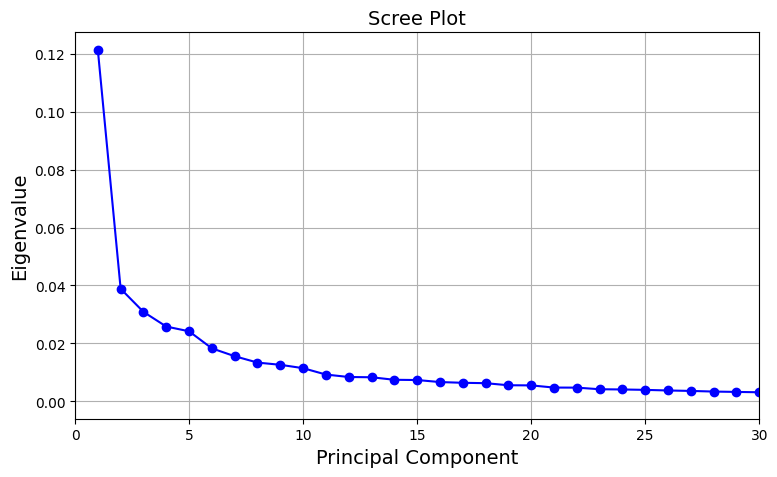

In [44]:
# Scree Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, marker='o', linestyle='-', color='blue')
plt.title("Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.xlim(0, 30)
plt.grid(True)
plt.tight_layout()
plt.show()

In [45]:
n_pca_components = 30  # set after reading Cell 3

def apply_pca_to_hog(df, n_components):
    hog_cols = [c for c in df.columns if c.startswith('hog_')]
    pca = PCA(n_components=n_components)
    hog_pca = pca.fit_transform(df[hog_cols])
    hog_pca_cols = pd.DataFrame(hog_pca, columns=[f'hog_pca_{i}' for i in range(hog_pca.shape[1])])
    df = pd.concat([df.drop(columns=hog_cols).reset_index(drop=True), hog_pca_cols], axis=1)
    return df, pca

def transform_pca_hog(df, pca):
    hog_cols = [c for c in df.columns if c.startswith('hog_')]
    hog_pca = pca.transform(df[hog_cols])
    hog_pca_cols = pd.DataFrame(hog_pca, columns=[f'hog_pca_{i}' for i in range(hog_pca.shape[1])])
    df = pd.concat([df.drop(columns=hog_cols).reset_index(drop=True), hog_pca_cols], axis=1)
    return df

In [46]:
train_set, pca = apply_pca_to_hog(train_set, n_pca_components)
test_set = transform_pca_hog(test_set, pca)

/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


ValueError: at least one array or dtype is required

In [ ]:
print([c for c in train_set.columns if c.startswith('hog_')])

In [ ]:
df_filtered_geo_data.head(5)

In [ ]:
from skimage.feature import local_binary_pattern

def extract_lbp(df, P=8, R=1, grid=(2, 2)):
    results = []
    n_bins = P + 2  # uniform LBP: P+2 possible pattern categories

    for path in df['path']:
        img = cv2.imread(str(path))
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        lbp = local_binary_pattern(gray, P, R, method='uniform')

        h, w = lbp.shape
        gh, gw = h // grid[0], w // grid[1]

        cell_hists = []
        for i in range(grid[0]):
            for j in range(grid[1]):
                cell = lbp[i*gh:(i+1)*gh, j*gw:(j+1)*gw]
                hist, _ = np.histogram(cell, bins=n_bins, range=(0, n_bins))
                cell_hists.extend(hist / hist.sum())

        results.append(cell_hists)

    lbp_cols = pd.DataFrame(results, columns=[f'lbp_{i}' for i in range(len(results[0]))])
    df = pd.concat([df.reset_index(drop=True), lbp_cols], axis=1)
    return df

In [ ]:
df_filtered_geo_data = extract_lbp(df_filtered_geo_data)

In [ ]:
feature_cols = [c for c in df_filtered_geo_data.columns if c.startswith(('hsv_', 'vari_', 'sky_'))]

corr_matrix = df_filtered_geo_data[feature_cols].corr()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = corr_pairs[corr_pairs.abs() > 0.7].sort_values(ascending=False)

print(high_corr)